# Machine learning-guided adaptive CPT investigation and economic benefit assessment

This experiment notebook follows one question: **can a model-guided investigation complete fewer planned CPTs while retaining the required prediction quality?** It compares five AI methods, evaluates sequential and adaptive stopping against the full candidate plan, and translates the observed work reduction into explicitly defined economic scenarios.

The public CPT measurements come from the [ISSMGE TC304 CPT database](https://tc304.org/cpt_databases.html). The prediction task covers 2–8 m, using 24 depth cells of 0.25 m. The research threshold qc < 1 MPa defines cumulative low-cone-resistance thickness; it is not a soil classification or a design safety criterion. The previous fixed-budget investigation remains available in the [v0.9.1 notebook](archive/CA6001_report_figures_v0.9.1.ipynb).

All findings below are read from the saved experimental CSV files. The independent unit is the site, with seeds averaged within site. These sites have a development history: the new results are a site-separated re-evaluation, rather than a newly collected blind test.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'src' / 'cpt_budget').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from cpt_budget.adaptive_display import (load_results, model_summary, evaluation,
                                        FIGURES, CAPTIONS, MODEL_NAMES, build)
tables = load_results(ROOT)
RESULTS = ROOT / 'results' / 'adaptive_v1'
FIG = RESULTS / 'figures'
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.precision', 4)


## Summary

The summary is computed from the saved evaluation decisions. An online trigger and a successful hidden audit are distinct outcomes; incorrect early stops remain in every decision and economic table. The main audit covers profile and cumulative-thickness targets; low-qc recall and false-positive targets are assessed separately.

In [2]:
decisions = evaluation(tables['decisions'])
adaptive = decisions.query("policy_id == 'P_adapt'").copy()
adaptive['reduction_pct'] = 100 * (adaptive.n_full - adaptive.n_stop) / adaptive.n_full
site_summary = adaptive.groupby('site_id').agg(
    planned_CPTs=('n_full', 'mean'), completed_CPTs=('n_stop', 'mean'),
    reduction_pct=('reduction_pct', 'mean'), audit_pass_rate=('audit_pass', 'mean'),
    incorrect_early_stops=('false_early_stop', 'sum'))
display(site_summary.round(3))
display(Markdown(f"The adaptive policy was evaluated at **{len(site_summary)} sites**. "
    f"The equal-site mean planned-CPT reduction was **{site_summary.reduction_pct.mean():.1f}%**. "
    f"There were **{int(adaptive.false_early_stop.sum())} incorrect early stops** among "
    f"{len(adaptive)} site–seed trajectories. Savings are interpreted together with these quality verdicts."))


,planned_CPTs,completed_CPTs,reduction_pct,audit_pass_rate,incorrect_early_stops
site_id,,,,,
christchurch_stadium,18.0,18.0,0.000,1.0,0
hollywood,20.0,20.0,0.000,1.0,0
newlock,64.0,64.0,0.000,0.0,0
wellington_airport,21.0,11.0,47.619,1.0,0


The adaptive policy was evaluated at **4 sites**. The equal-site mean planned-CPT reduction was **11.9%**. There were **0 incorrect early stops** among 12 site–seed trajectories. Savings are interpreted together with these quality verdicts.

## Context and methods

The same initial CPTs, candidate pool and hidden audit set are used for all policies. The full plan completes every initial and selectable CPT; the hidden audit CPTs are excluded from the plan count. Sequential investigation adds maximin locations. Adaptive investigation ranks uncertainty, model disagreement and distance. Both incremental policies apply the same frozen stopping rule.

Online stability is measured by the 90th-percentile changes in log(qc) and cumulative thickness on a fixed query grid. The rule also checks held-out support-group error, the uncertainty quantile, the minimum observation count and spatial coverage. All conditions must hold for two consecutive rounds; the hidden audit is not one of these signals.

### Key assumptions

Only revealed CPT curves and pre-known coordinates enter selection and stopping. Hidden audit labels are read by a separate evaluator. The economic comparator is the frozen complete candidate plan, not an assumed 13-CPT endpoint. The main economic scenario uses α = 1; α = 0.5 and 0.75 are also assessed. A daily scenario benefit is not an observed financial return.

wrote fig01_workflow


wrote fig02_dataset


wrote fig03_selection_maps


wrote fig04_five_models


wrote fig05_quality_vs_cpts


wrote fig06_site_outcomes


wrote fig07_economics


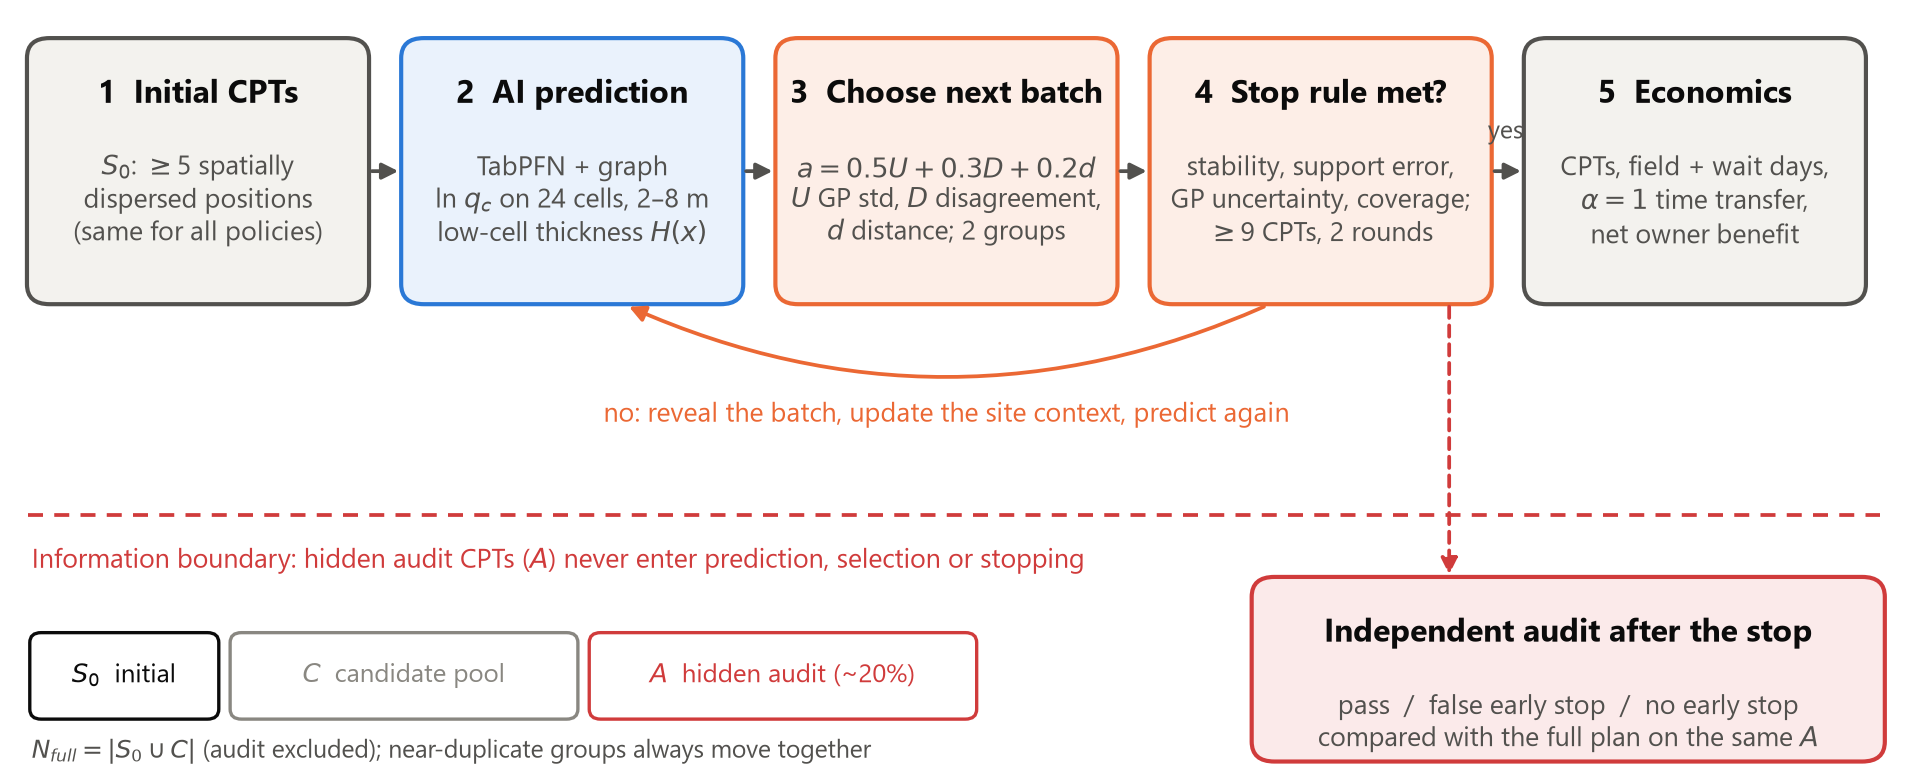

**Figure 1.** Investigation loop. Revealed CPTs feed prediction, batch selection and an online stop rule; the hidden audit set A is read only by a separate evaluator after the stop. All policies share S0, C and A.

,Frozen online stopping setting
delta_q90_max,0.0815
delta_h90_max,0.0000
support_log_mae_max,0.5837
uncertainty_q90_max,0.4613
min_observed,9.0000
consecutive_rounds,2.0000


In [3]:
build(ROOT, notebook=False)
display(Image(filename=str(FIG / (FIGURES[0]+'.png'))))
display(Markdown('**Figure 1.** '+CAPTIONS[0]))
frozen = json.loads((RESULTS / 'frozen_config.json').read_text(encoding='utf-8'))
display(pd.Series(frozen['stop_rule'], name='Frozen online stopping setting').to_frame())

## Data and separation

The data manifest reports the actual usable records and the location-group split. Depth cells are repeated measurements within a CPT, not independent observations. Development and evaluation roles are retained in the tables; model selection and stopping thresholds use development data only.

,display_name,n_profiles,n_planned_locations,n_locations,n_near_groups,adaptive_role
0,Aranui,5,5,5,5,source_only
1,Avondale,9,9,9,9,source_only
2,Avonside,10,10,10,9,source_only
3,Baytown,3,3,3,3,source_only
4,Bexley,14,14,14,9,source_only
5,Cashmere (high school),18,18,18,18,source_only
6,Christchurch (Central City),18,18,18,17,source_only
7,Christchurch (Cnr Armagh & Durham St),7,7,5,4,source_only
8,Christchurch Metro Sports Facility,39,39,39,35,development
9,Christchurch Stadium,30,23,23,20,evaluation


role                                     audit  candidate  initial
site_id                            seed                           
christchurch_metro_sports_facility 17        8         26        5
                                   29        8         26        5
                                   43        8         26        5
christchurch_stadium               17        5         13        5
                                   29        5         13        5
                                   43        5         12        6
hollywood                          17        5         14        6
                                   29        5         13        7
                                   43        5         14        6
lower_hutt_town_hall               17        6         18        5
                                   29        6         18        5
                                   43        6         18        5
marshland                          17        4         11        5
                                   29        4         11        5
                                   43        4         11        5
newlock                            17       16         58        6
                                   29       16         59        5
                                   43       16         58        6
tauranga_farmers_building          17        6         17        5
                                   29        6         17        5
                                   43        6         17        5
wellington_airport                 17        6         16        5
                                   29        6         16        5
                                   43        6         16        5

Across **492 usable profiles**, the 0.25 m representation had a mean absolute cumulative-thickness difference of **0.092 m** from measurement-derived integration. A 0.1 m diagnostic grid reduced this representation difference to **0.033 m**, but the present five-method comparison consistently retains the 0.25 m grid. This is a representation check, not a model accuracy claim or an independent geological truth.

,site_id,n_profiles,grid_025_mae_m,grid_025_p90_abs_error_m,grid_010_diagnostic_mae_m
0,ALL,492,0.0925,0.2565,0.0335
9,christchurch_metro_sports_facility,39,0.1443,0.2920,0.0629
10,christchurch_stadium,23,0.1291,0.3343,0.0413
12,hollywood,25,0.0578,0.1536,0.0137
15,lower_hutt_town_hall,29,0.0634,0.1800,0.0349
16,marshland,20,0.1354,0.3278,0.0436
19,newlock,80,0.1389,0.3250,0.0437
26,tauranga_farmers_building,28,0.1925,0.3562,0.0571
29,wellington_airport,27,0.0016,0.0000,0.0021


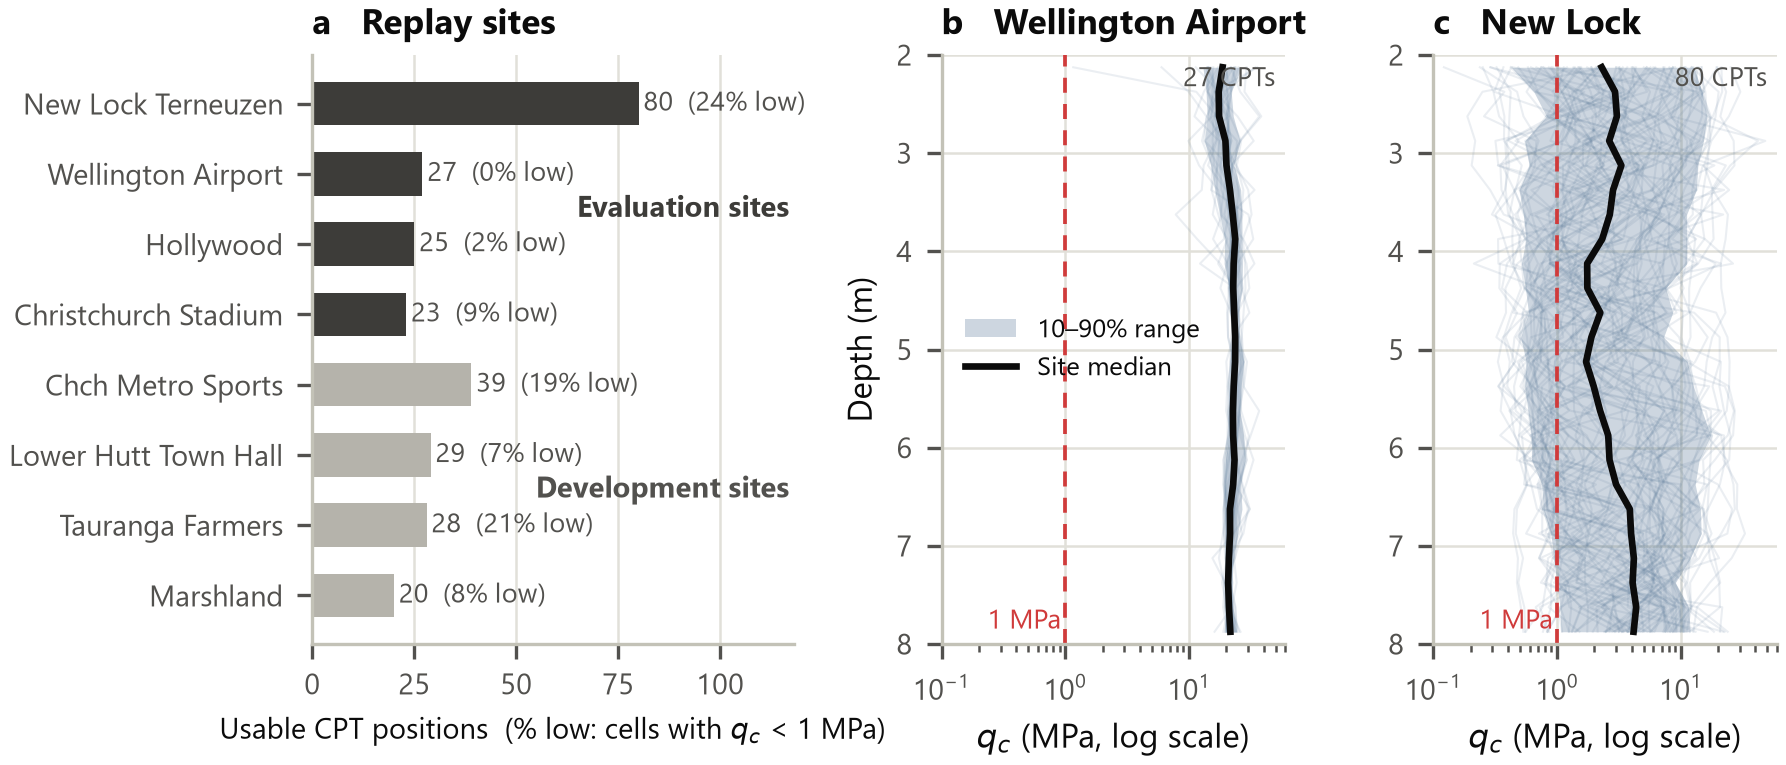

**Figure 2.** Data. (a) Usable CPT positions at the eight replay sites and their share of qc < 1 MPa cells. (b, c) All 2-8 m profiles at the easiest (Wellington Airport) and hardest (New Lock) evaluation sites.

In [4]:
site_manifest = pd.read_csv(RESULTS / 'site_manifest.csv')
display(site_manifest[['display_name', 'n_profiles', 'n_planned_locations',
                       'n_locations', 'n_near_groups', 'adaptive_role']])
display(tables['locations'].groupby(['site_id', 'seed', 'role']).size().unstack(fill_value=0))
representation = pd.read_csv(RESULTS / 'representation_summary.csv')
overall = representation.query("site_id == 'ALL'").iloc[0]
display(Markdown(f"Across **{int(overall.n_profiles)} usable profiles**, the 0.25 m representation "
    f"had a mean absolute cumulative-thickness difference of **{overall.grid_025_mae_m:.3f} m** "
    f"from measurement-derived integration. A 0.1 m diagnostic grid reduced this representation "
    f"difference to **{overall.grid_010_diagnostic_mae_m:.3f} m**, but the present five-method "
    f"comparison consistently retains the 0.25 m grid. This is a representation check, not a model "
    f"accuracy claim or an independent geological truth."))
display(representation.loc[representation.site_id.isin(['ALL'] + tables['locations'].site_id.unique().tolist()),
    ['site_id', 'n_profiles', 'grid_025_mae_m', 'grid_025_p90_abs_error_m', 'grid_010_diagnostic_mae_m']])
display(Image(filename=str(FIG / (FIGURES[1]+'.png'))))
display(Markdown('**Figure 2.** '+CAPTIONS[1]))

## AI methods and common-sequence comparison

**GP** models spatial correlations and provides a probabilistic uncertainty signal. **XGBoost residual** learns nonlinear corrections to the spatial base from observed-neighbour features. **CNP** aggregates the revealed support set into a conditional neural representation. **TabPFN joint** combines a trained residual component with a spatial base and profile-level decisions. **TabPFN + graph** combines residual prediction with robust graph smoothing. These hybrid methods retain their spatial components: the whole improvement cannot be attributed to the Transformer alone.

For the five-method comparison, all methods receive the same CPT sequence. Site means include the common budgets and seeds; the overall comparison gives each site equal weight.

,log_mae,thickness_mae_m,recall,fpr
model_id,,,,
gp,0.5093,0.4003,0.1403,0.0188
xgb,0.5118,0.4851,0.3123,0.0689
cnp,0.6566,0.4305,0.0000,0.0000
tabpfn_joint,0.4971,0.4914,0.3330,0.0780
tabpfn_graph,0.5025,0.5947,0.3628,0.0965


The development-selected primary method was **TabPFN + graph**. In the evaluation comparison, the lowest profile error was obtained by **TabPFN joint**, whereas the lowest thickness error was obtained by **GP**. The primary method is retained after evaluation; it is not re-selected from these outcomes.

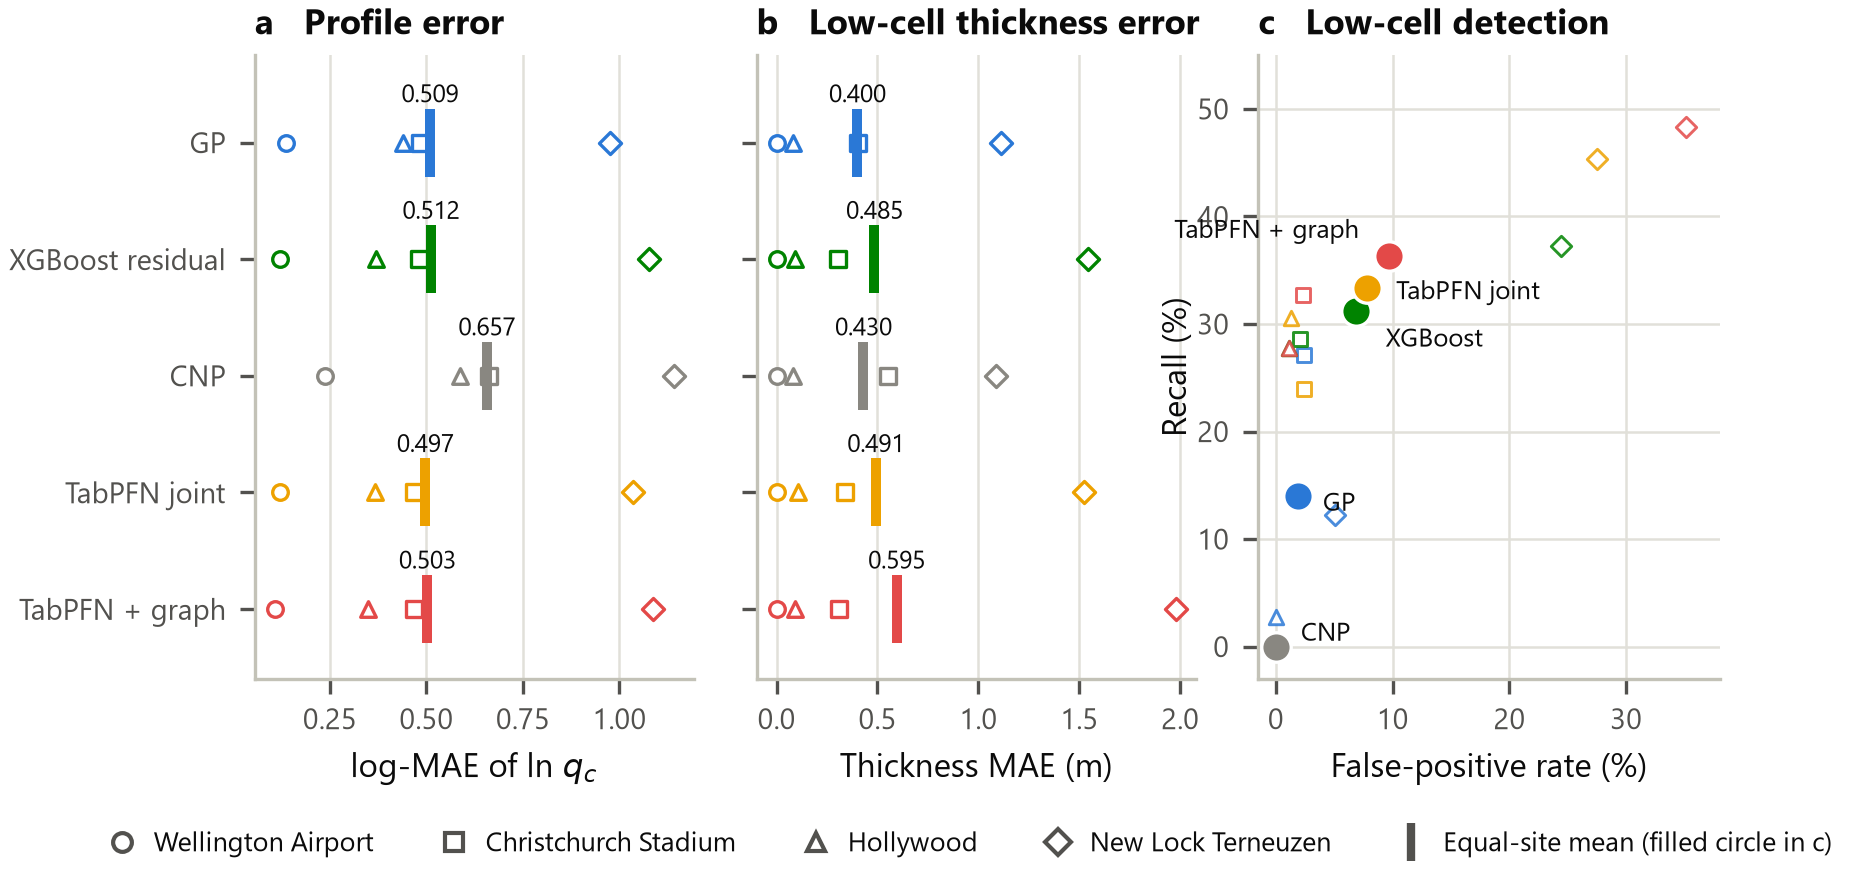

**Figure 4.** Five AI methods on identical observation states at the four evaluation sites. Open marks are site means; bars and filled circles are the equal-site mean. Recall is undefined at Wellington Airport (no low-qc cells).

In [5]:
site_models, model_means = model_summary(tables['model_comparison'])
display(model_means.round(4))
primary = tables['joined'].model_id.iloc[0]
best_profile = model_means.log_mae.idxmin()
best_thickness = model_means.thickness_mae_m.idxmin()
display(Markdown(f'The development-selected primary method was **{MODEL_NAMES.get(primary, primary)}**. In the evaluation comparison, the lowest profile error was obtained by **{MODEL_NAMES.get(best_profile, best_profile)}**, whereas the lowest thickness error was obtained by **{MODEL_NAMES.get(best_thickness, best_thickness)}**. The primary method is retained after evaluation; it is not re-selected from these outcomes.'))
display(Image(filename=str(FIG / (FIGURES[3]+'.png'))))
display(Markdown('**Figure 4.** '+CAPTIONS[3]))

### Weight fine-tuning and component ablation

The matched ablation separates gradient-updated weights from the spatial guard and joint profile decision. Context fitting alone is not described as weight fine-tuning. The results are compared on the same evaluation observation states; a benefit is reported only where it is observed.

In [6]:
if not tables['ablation'].empty:
    _, ablation_means = model_summary(tables['ablation'], restricted=False)
    ablation_means.loc['tabpfn_joint'] = model_means.loc['tabpfn_joint']
    display(ablation_means.round(4))
    if 'tabpfn_joint_unfinetuned' in ablation_means.index:
        unfine = ablation_means.loc['tabpfn_joint_unfinetuned', 'log_mae']
        fine = ablation_means.loc['tabpfn_joint', 'log_mae']
        display(Markdown(f'The joint method had evaluation log-MAE **{fine:.4f}** with the stored '
            f'fine-tuned weights and **{unfine:.4f}** with the matched non-fine-tuned weights. '
            f'This comparison is retained even when the non-fine-tuned variant performs better.'))

,log_mae,thickness_mae_m,recall,fpr
model_id,,,,
tabpfn_residual_raw,0.5024,0.5090,0.2239,0.0600
tabpfn_residual_guarded,0.5029,0.4973,0.3207,0.0730
tabpfn_residual_unfinetuned,0.5065,0.4943,0.2340,0.0586
tabpfn_joint_unfinetuned,0.4954,0.4796,0.3492,0.0746
tabpfn_joint,0.4971,0.4914,0.3330,0.0780


The joint method had evaluation log-MAE **0.4971** with the stored fine-tuned weights and **0.4954** with the matched non-fine-tuned weights. This comparison is retained even when the non-fine-tuned variant performs better.

## Selection and stopping

The maps retain the distinction between initial, selectable and hidden audit locations. Wellington Airport shows an actual online stop; New Lock is the pre-specified engineering case, irrespective of its result. The accompanying quality curves use the same audit CPTs at every round.

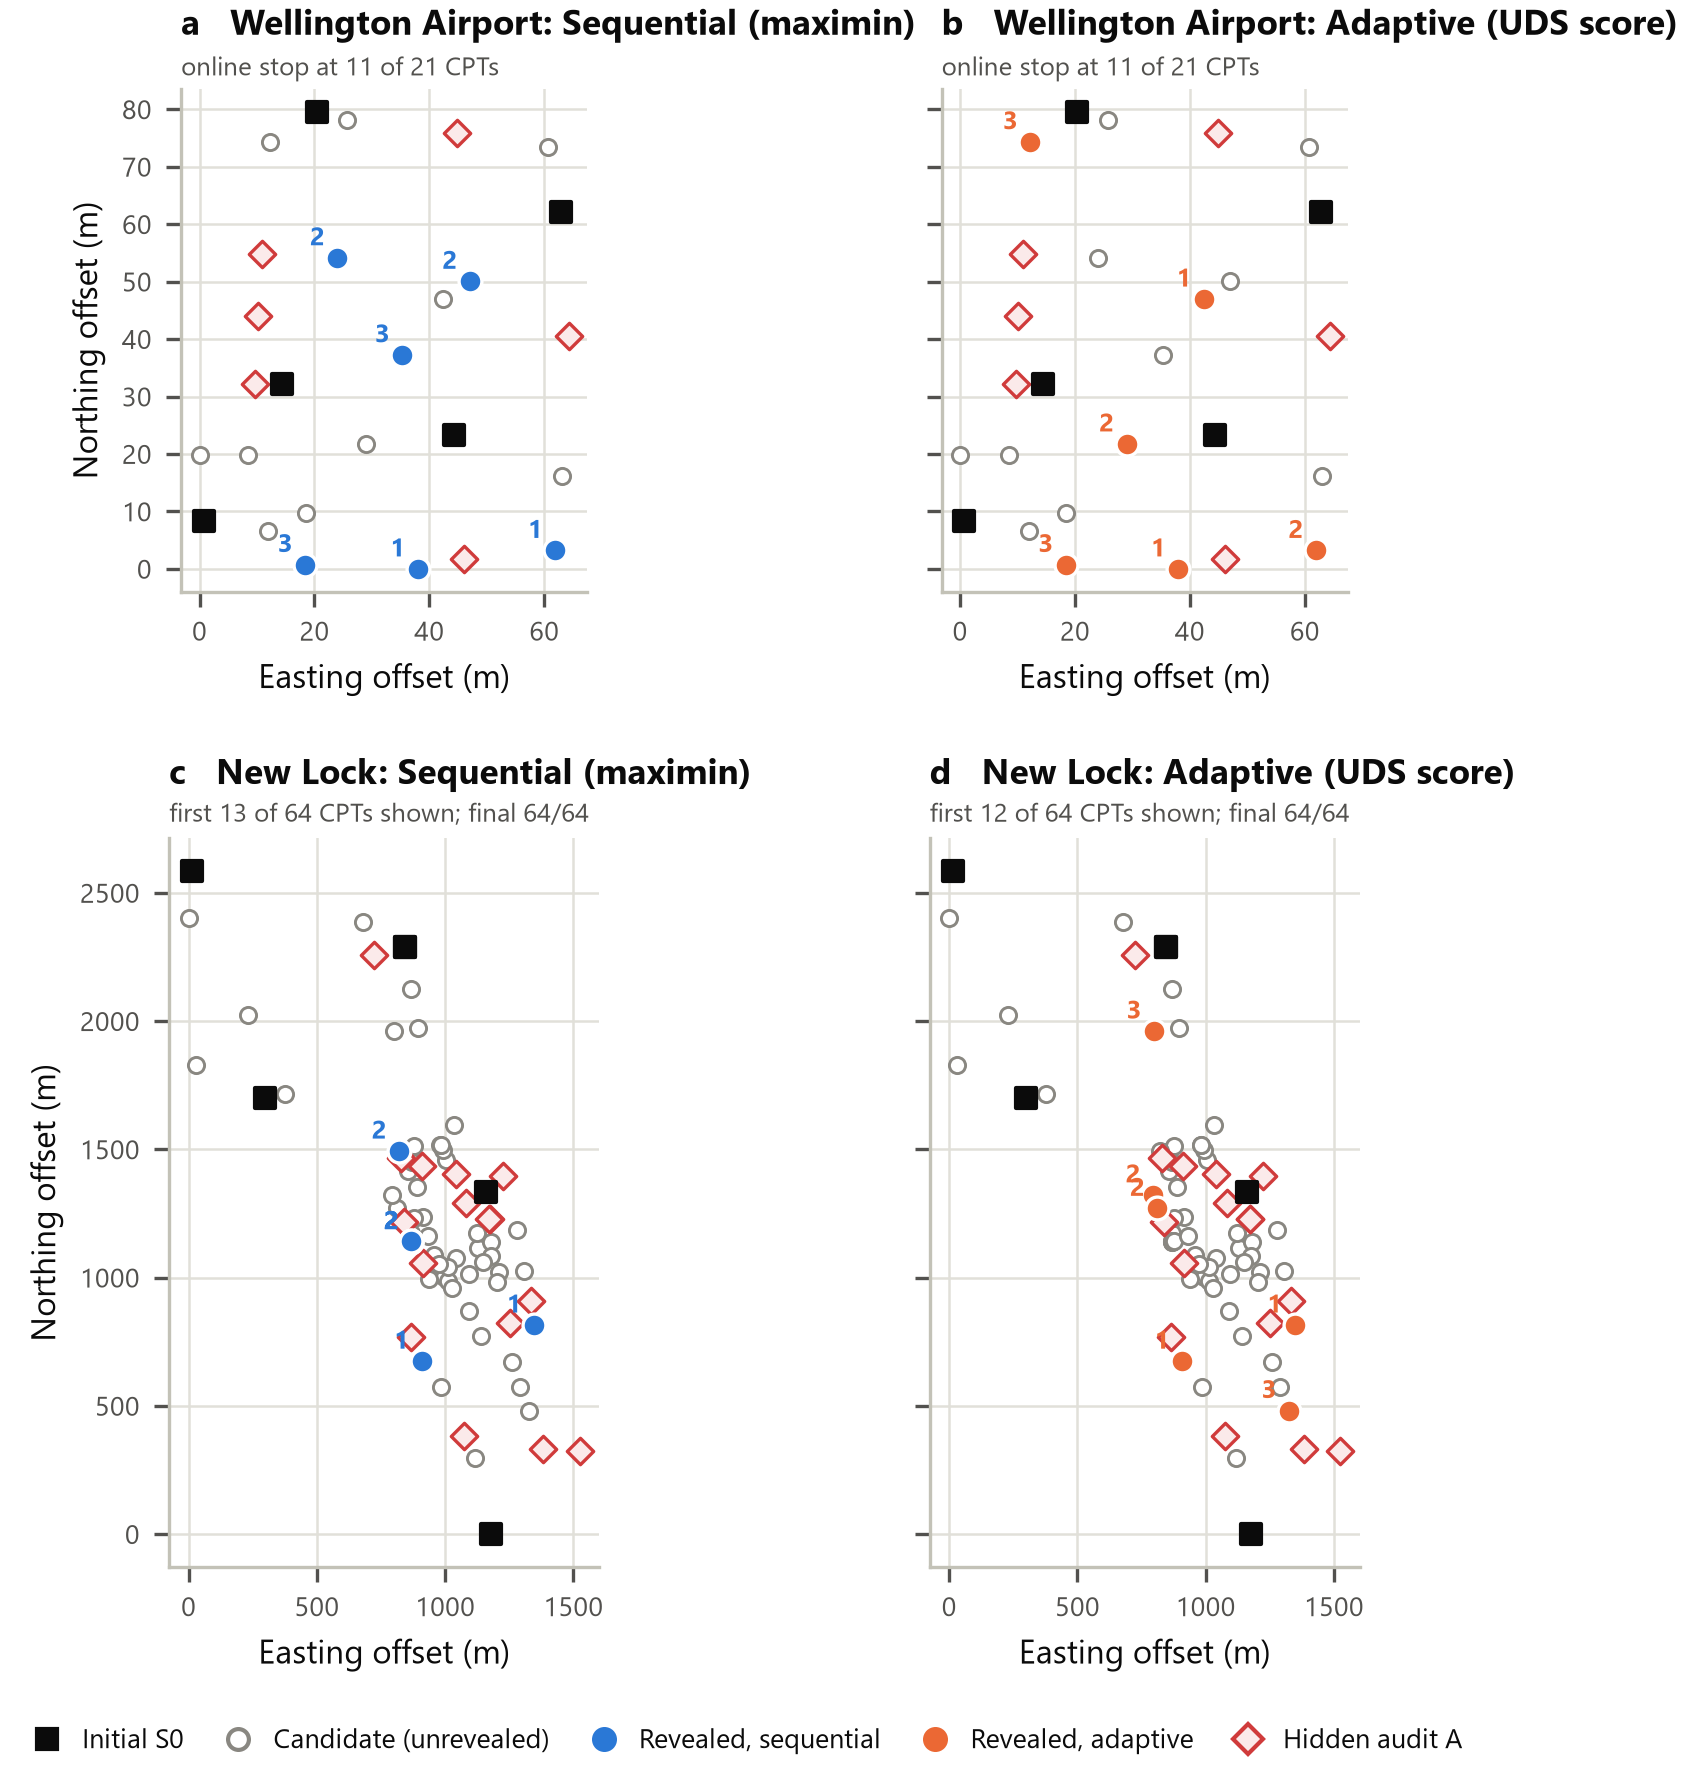

**Figure 3.** Selection maps, seed 17. Wellington Airport (a, b) at the online stop; New Lock (c, d) after the first 12-13 CPTs. Numbers give the round in which a position was revealed.

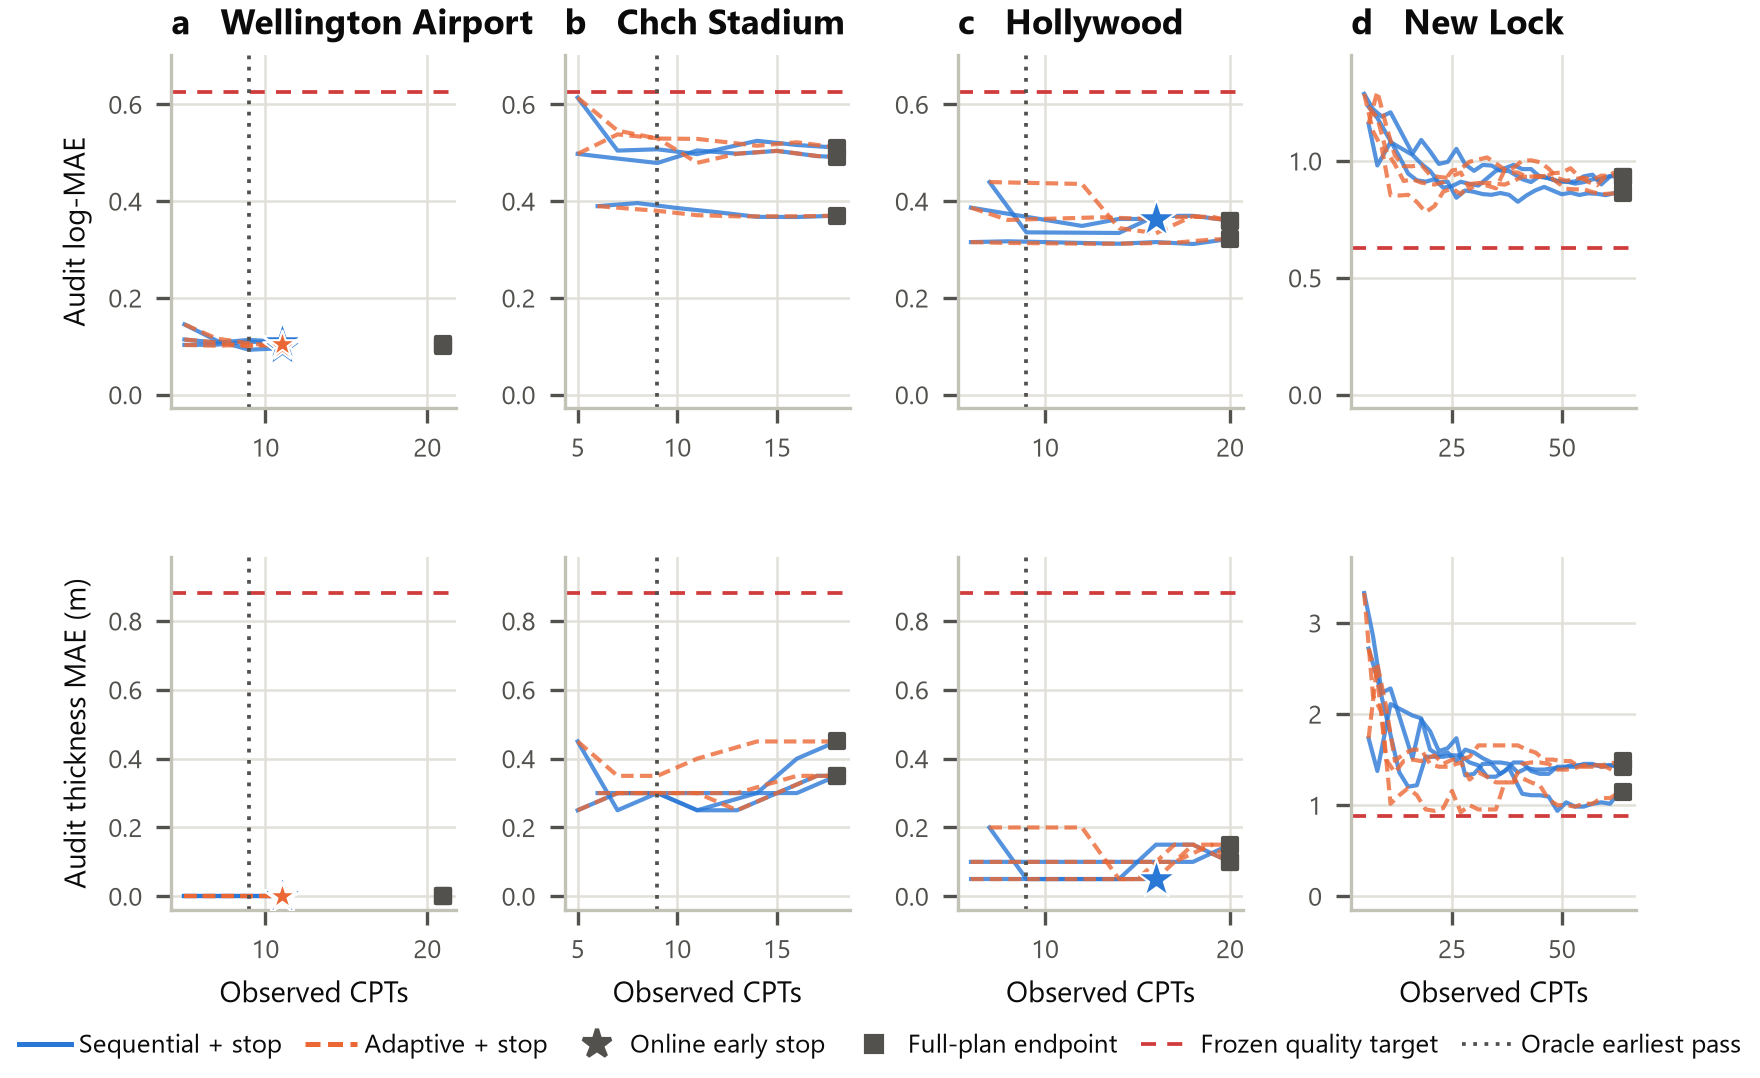

**Figure 5.** Hidden-audit quality as CPTs are added (three seeds per policy). Stars mark online early stops; squares the full-plan endpoint; the red line the frozen target; the dotted line the oracle earliest passing count (uses hidden labels, diagnostic only).

,log_mae,thickness_mae_m,recall,fpr
model_id,,,,
cnp,1.1349,1.0885,0.0000,0.0000
gp,0.8365,0.9948,0.0722,0.0073
tabpfn_graph,0.9096,1.3490,0.3530,0.1829
tabpfn_joint,0.8639,1.0833,0.2764,0.1211
xgb,0.9137,1.1094,0.2776,0.1138


The full-plan New Lock comparison retains all five methods. Complete candidate-plan observations do not automatically guarantee accurate prediction at the separate hidden audit CPTs.

In [7]:
display(Image(filename=str(FIG / (FIGURES[2]+'.png'))))
display(Markdown('**Figure 3.** '+CAPTIONS[2]))
display(Image(filename=str(FIG / (FIGURES[4]+'.png'))))
display(Markdown('**Figure 5.** '+CAPTIONS[4]))
full_case = evaluation(tables['full_plan_model_sensitivity']).query("site_id == 'newlock'")
if not full_case.empty:
    display(full_case.groupby('model_id')[['log_mae', 'thickness_mae_m', 'recall', 'fpr']].mean().round(4))
    display(Markdown('The full-plan New Lock comparison retains all five methods. Complete candidate-plan observations do not automatically guarantee accurate prediction at the separate hidden audit CPTs.'))

## Site outcomes

Early stopping is counted as successful only when the hidden audit passes. Failure cases and complete-plan outcomes remain visible. An advantage over the full plan may arise from early stopping itself; the matched sequential policy identifies any additional contribution from adaptive location choice.

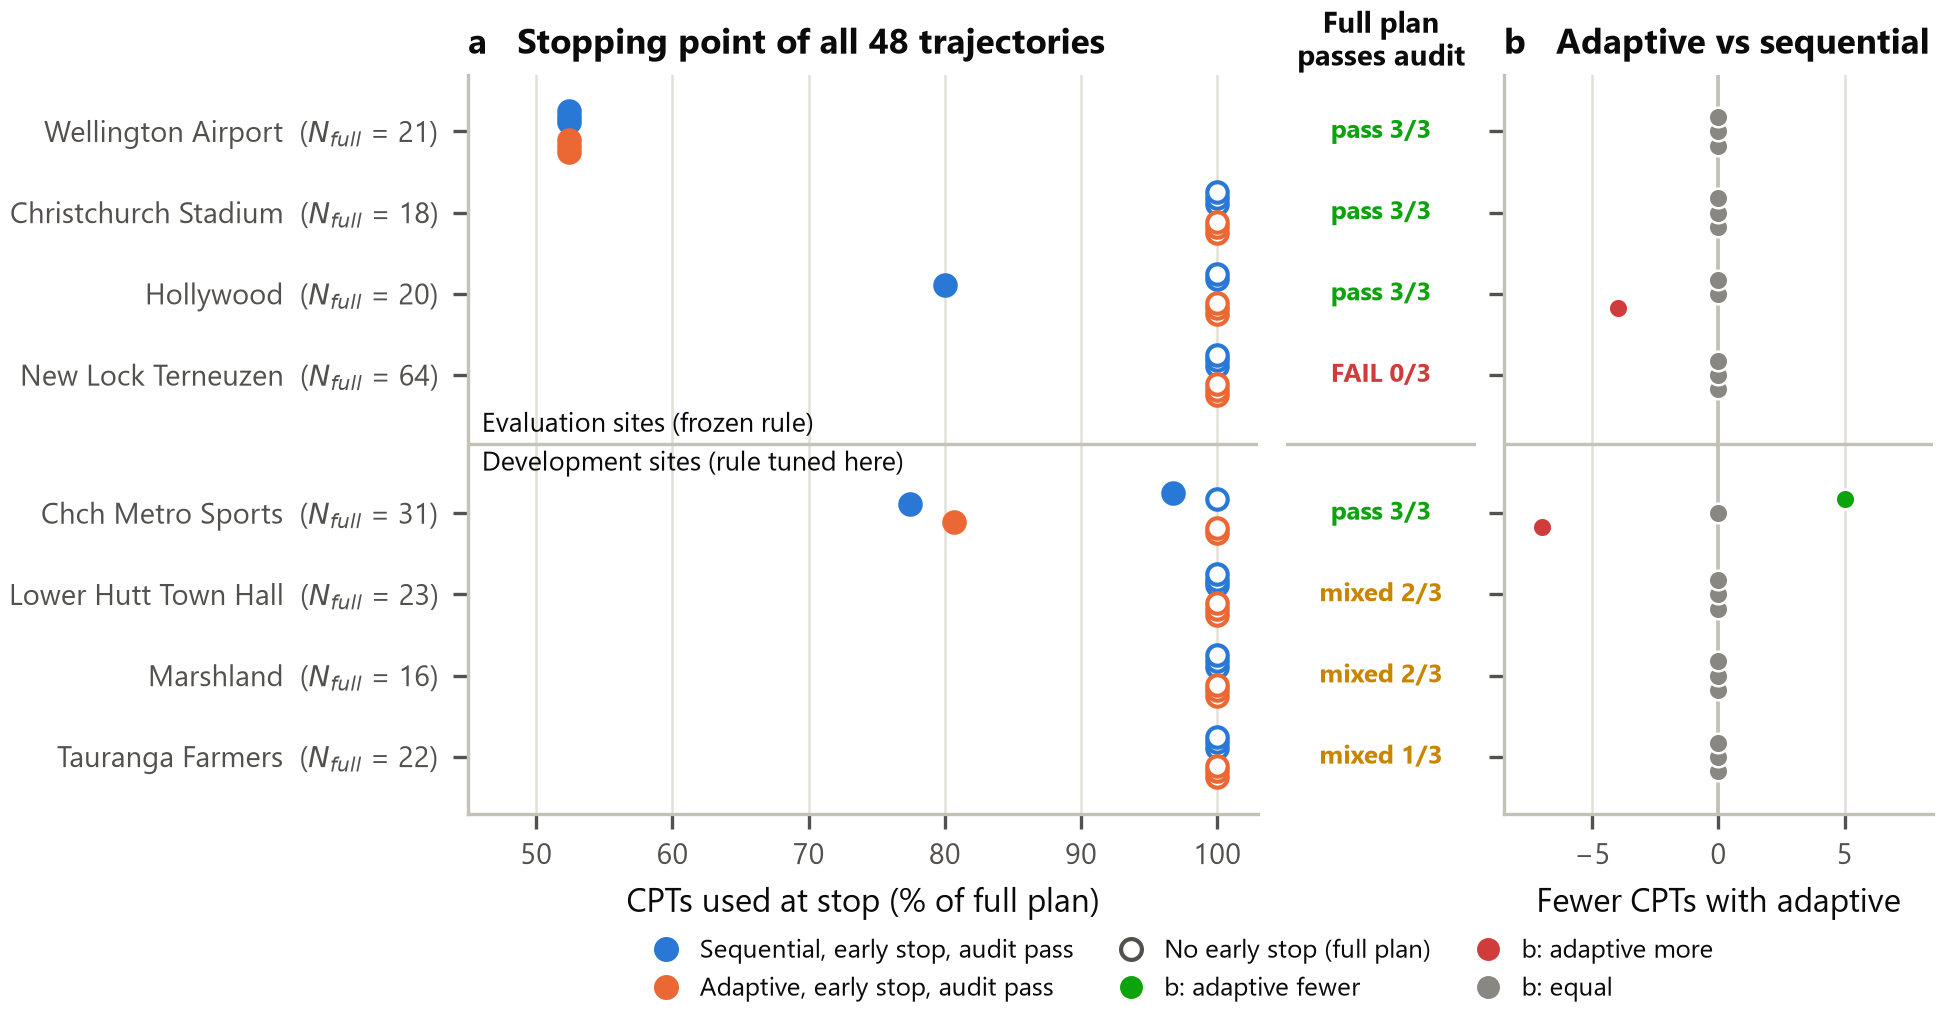

**Figure 6.** Decision outcomes for all 48 sequential and adaptive trajectories. (a) CPTs used at the stop and the full-plan audit verdict per site; (b) CPTs saved by adaptive relative to sequential, paired by seed.

,site_id,seed,policy_id,n_full,n_stop,audit_pass,low_qc_audit_pass,false_early_stop
36,christchurch_stadium,17,B_full,18,18,True,False,False
37,christchurch_stadium,17,B_seq,18,18,True,False,False
38,christchurch_stadium,17,P_adapt,18,18,True,False,False
39,christchurch_stadium,29,B_full,18,18,True,False,False
40,christchurch_stadium,29,B_seq,18,18,True,False,False
41,christchurch_stadium,29,P_adapt,18,18,True,False,False
42,christchurch_stadium,43,B_full,18,18,True,False,False
43,christchurch_stadium,43,B_seq,18,18,True,False,False
44,christchurch_stadium,43,P_adapt,18,18,True,False,False
45,hollywood,17,B_full,20,20,True,False,False


policy_id,B_full,B_seq,P_adapt,Additional_adaptive_saving
site_id,,,,
christchurch_stadium,18.0,18.000,18.0,0.000
hollywood,20.0,18.667,20.0,-1.333
newlock,64.0,64.000,64.0,0.000
wellington_airport,21.0,11.000,11.0,0.000


In [8]:
display(Image(filename=str(FIG / (FIGURES[5]+'.png'))))
display(Markdown('**Figure 6.** '+CAPTIONS[5]))
display(decisions[[c for c in ['site_id', 'seed', 'policy_id', 'n_full', 'n_stop', 'audit_pass', 'low_qc_audit_pass', 'false_early_stop'] if c in decisions]])
paired = decisions.pivot(index=['site_id', 'seed'], columns='policy_id', values='n_stop')
paired['Additional_adaptive_saving'] = paired.B_seq - paired.P_adapt
display(paired.groupby('site_id').mean().round(3))

## Economic consequences and sensitivity

The economic calculation starts from experimentally observed CPT counts. It separates direct investigation savings, project-time costs, earlier-use benefits and AI/verification costs. The project-time transfer coefficient α connects investigation time saved to project time saved. These values are scenario assessments with explicit cost assumptions; an incorrect early stop is retained and can incur verification or return-visit costs.

,site_id,policy_id,n_full,n_stop,saved_cpt,investigation_days_saved,project_days_saved,direct_saving,project_time_saving,early_opening_benefit,ai_incremental_cost,net_benefit
36,christchurch_stadium,B_full,18,18,0,0.00,0.00,0.0,0.0,0.0,0.0,0.0
37,christchurch_stadium,B_seq,18,18,0,-1.75,-1.75,0.0,-8750.0,-5250.0,600.0,-14600.0
38,christchurch_stadium,P_adapt,18,18,0,-1.75,-1.75,0.0,-8750.0,-5250.0,600.0,-14600.0
39,christchurch_stadium,B_full,18,18,0,0.00,0.00,0.0,0.0,0.0,0.0,0.0
40,christchurch_stadium,B_seq,18,18,0,-1.50,-1.50,0.0,-7500.0,-4500.0,600.0,-12600.0
41,christchurch_stadium,P_adapt,18,18,0,-1.50,-1.50,0.0,-7500.0,-4500.0,600.0,-12600.0
42,christchurch_stadium,B_full,18,18,0,0.00,0.00,0.0,0.0,0.0,0.0,0.0
43,christchurch_stadium,B_seq,18,18,0,-1.50,-1.50,0.0,-7500.0,-4500.0,600.0,-12600.0
44,christchurch_stadium,P_adapt,18,18,0,-1.25,-1.25,0.0,-6250.0,-3750.0,600.0,-10600.0
45,hollywood,B_full,20,20,0,0.00,0.00,0.0,0.0,0.0,0.0,0.0


,parameter,value,unit,source_type,source_url
0,cost_per_cpt,750.00,EUR/CPT,explicit_scenario_assumption,NaN
1,plan_depth_m,20.00,m/CPT,explicit_scenario_assumption,NaN
2,mobilization_cost,560.00,EUR/visit,local_quote_transfer_assumption,https://www.spieghelhoek.nl/wp-content/uploads/2025/08/offerte-Mos-Realisati...
3,cpt_per_rig_workday,5.00,CPT/rig/workday,explicit_scenario_assumption,NaN
4,parallel_rigs,1.00,rigs,explicit_scenario_assumption,NaN
5,batch_wait_calendar_days,0.25,calendar_day/interbatch_transition,explicit_scenario_assumption,NaN
6,review_workdays_per_batch,0.00,workday/batch,explicit_scenario_assumption,NaN
7,project_cost_per_calendar_day,5000.00,EUR/calendar_day,explicit_scenario_assumption,NaN
8,opening_net_per_calendar_day,3000.00,EUR/calendar_day,explicit_scenario_assumption,NaN
9,ai_incremental_cost,600.00,EUR/trajectory,explicit_scenario_assumption,https://www.spieghelhoek.nl/wp-content/uploads/2025/08/offerte-Mos-Realisati...


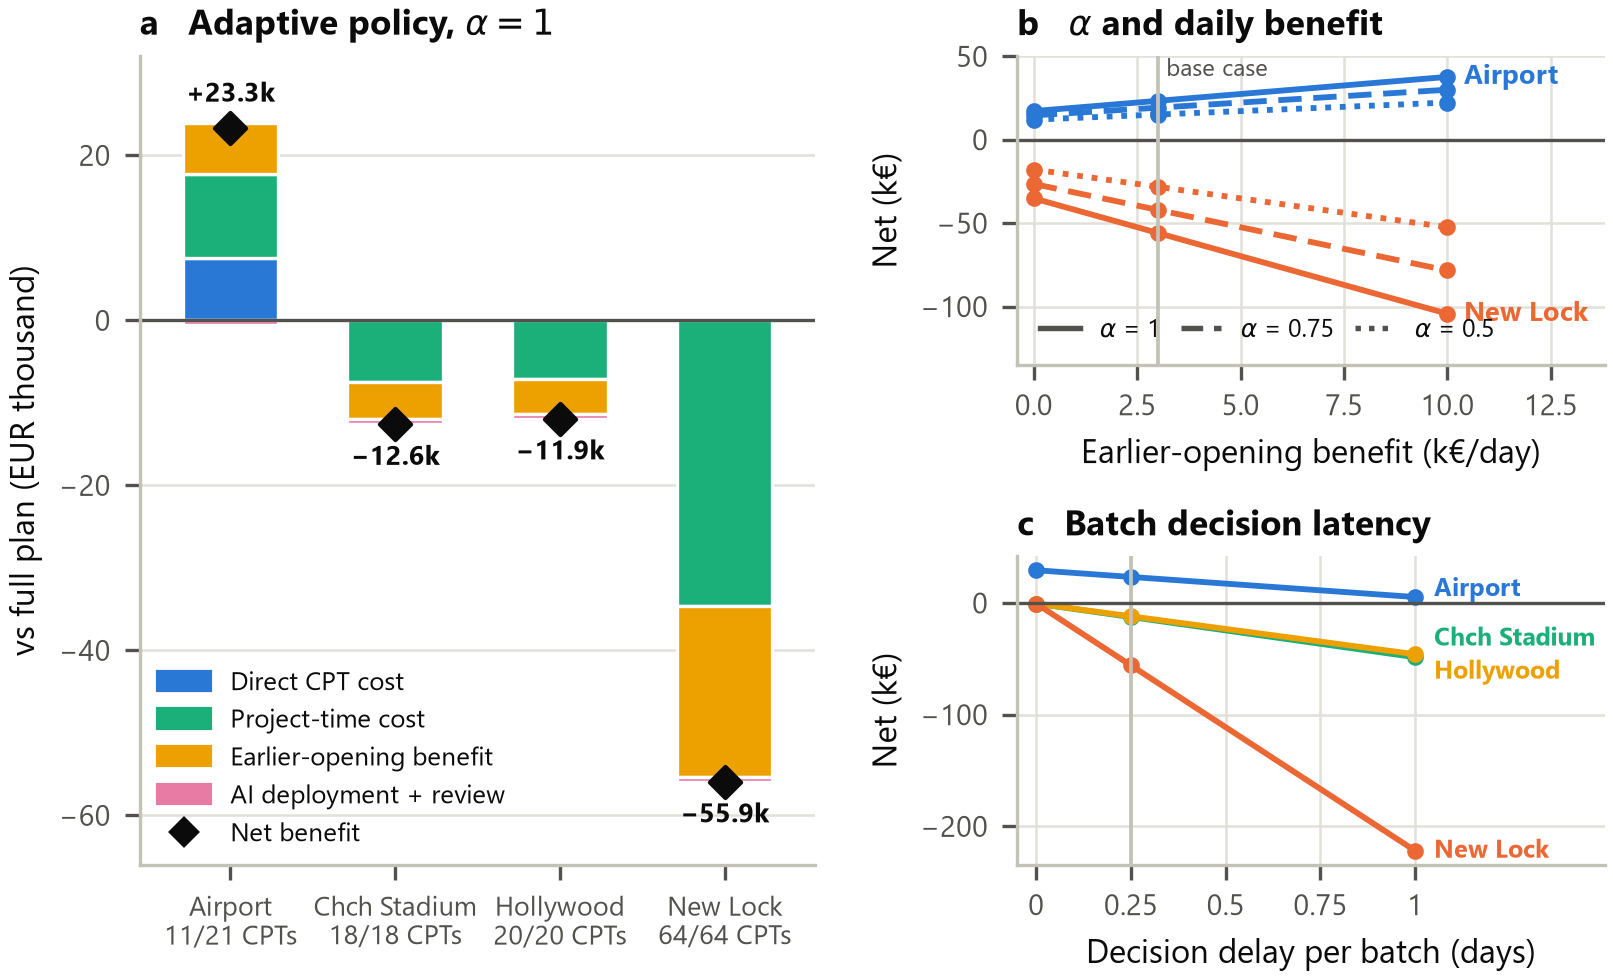

**Figure 7.** Owner-financial scenario, EUR 2025, adaptive policy (mean of three seeds). (a) Benefit components relative to the full plan at alpha = 1. (b) Net benefit as alpha and the daily earlier-opening benefit vary (vertical line: base case). (c) Net benefit against the decision delay per batch.

count      mean       min      max
sensitivity_kind   alpha                                    
alpha              0.50      72  -4695.83  -29600.0  15100.0
                   0.75      72  -7250.00  -44100.0  19200.0
                   1.00      72  -9804.17  -58600.0  23300.0
alpha_opening_grid 0.50     216  -5547.22  -54975.0  22275.0
                   0.75     216  -8527.08  -82162.5  29962.5
                   1.00     216 -11506.94 -109350.0  37650.0
one_at_a_time      1.00    1152 -12162.02 -232600.0  43800.0

In [9]:
cols = [c for c in ['site_id', 'policy_id', 'n_full', 'n_stop', 'saved_cpt', 'investigation_days_saved', 'project_days_saved', 'direct_saving', 'project_time_saving', 'early_opening_benefit', 'ai_incremental_cost', 'net_benefit'] if c in tables['economic_results']]
display(evaluation(tables['economic_results'])[cols])
if not tables['economic_inputs'].empty:
    display(tables['economic_inputs'][[c for c in ['parameter', 'value', 'unit', 'source_type', 'source_url'] if c in tables['economic_inputs']]])
if (FIG / (FIGURES[6]+'.png')).exists():
    display(Image(filename=str(FIG / (FIGURES[6]+'.png'))))
    display(Markdown('**Figure 7.** '+CAPTIONS[6]))
display(tables['sensitivity'].groupby(['sensitivity_kind', 'alpha']).net_benefit.agg(['count', 'mean', 'min', 'max']).round(2))

## Interpretation

The engineering result has three parts: prediction quality, the completed planned-CPT count, and the hidden-audit verdict. An investigation that stops early but fails audit does not establish a deployable saving. Where sequential and adaptive outcomes are similar, the gain is mainly due to staged investigation and stopping. Where adaptive sampling passes audit with fewer CPTs, it supports an additional benefit from selecting informative locations.

Low-qc detection is difficult when thin or laterally variable features are sparsely observed. The reported recall, false-positive rate and thickness error therefore accompany profile error throughout the comparison. The evidence applies to the measured 2–8 m reconstruction task and the defined economic scenarios.

## Reproducibility and sources

The figures are generated by `cpt_budget.report_figures` from `results/adaptive_v1/*.csv`. SVG and PDF files retain editable text; PNG previews are saved for this notebook. Original measurements: ISSMGE TC304 CPT database. Model references and the project background and economic parameter sources are recorded in the execution plan and economic parameter document. The previous investigation's notebook, HTML and result files are retained as historical evidence.